# Exploratory Data Analysis & Visualization of the Breast Cancer Wisconsin (Diagnostic) Dataset
**Course:** U21ADP05 – Exploratory Data Analysis and Visualization | **Assignment II – Case Study**

This notebook covers the full project flow:
1. Acquire → 2. Parse → 3. Filter (clean) → 4. Mine (statistics) → 5. Represent (visuals) → 6. Refine → 7. Interact
followed by deep-learning model building (MLP), hyper-parameter tuning, and evaluation visualisations.

*Run order: top to bottom. All figures are saved into `figures/`, tables into `outputs/`.*

In [1]:
# ---------------------------------------------------------------- 0. SETUP
import os, json, copy, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
IN_NB = "get_ipython" in globals()          # True when running inside Jupyter
if not IN_NB:
    matplotlib.use("Agg")                    # headless backend when run as a plain .py script
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, confusion_matrix, log_loss,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:                          # plain-python fallback
    display = print

SEED = 42
np.random.seed(SEED)

# ---- project paths (works from the repo root, notebooks/ or src/) ----
ROOT = Path.cwd()
if ROOT.name in ("notebooks", "src"):
    ROOT = ROOT.parent
DATA, PROC, FIG, OUT, INTER = (ROOT / "data", ROOT / "data" / "processed",
                               ROOT / "figures", ROOT / "outputs", ROOT / "interactive")
for p in (DATA, PROC, FIG, OUT, INTER):
    p.mkdir(parents=True, exist_ok=True)

# ---- consistent, colour-blind-safe visual style (Okabe-Ito palette) ----
PALETTE = {"B": "#0072B2", "M": "#D55E00"}   # Benign = blue, Malignant = vermillion
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 14)
metrics = {}                                  # collects every number reported in the project report


def finish(name):
    """Save the current figure into figures/ and display it."""
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show() if IN_NB else plt.close()

## STAGE 1 – ACQUIRE
**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI Machine Learning Repository (Wolberg, Street & Mangasarian).
Features are computed from digitised images of fine-needle-aspirate (FNA) of breast masses and describe the cell nuclei.
The CSV is stored in `data/`; if it is missing it is regenerated from scikit-learn's bundled copy of the same UCI data.

In [2]:
CSV = DATA / "breast_cancer_wisconsin.csv"
if not CSV.exists():
    raw = load_breast_cancer(as_frame=True).frame
    raw.columns = [c.replace(" ", "_") for c in raw.columns]
    # scikit-learn encodes target 0 = malignant, 1 = benign -> convert to the original M / B labels
    raw["diagnosis"] = np.where(raw["target"] == 0, "M", "B")
    raw = raw.drop(columns="target")
    raw.to_csv(CSV, index=False)
df = pd.read_csv(CSV)
print("Loaded:", CSV.name, "| shape =", df.shape)
display(df.head())

Loaded: breast_cancer_wisconsin.csv | shape = (569, 31)
   mean_radius  mean_texture  mean_perimeter  mean_area  mean_smoothness  mean_compactness  mean_concavity  ...  worst_smoothness  worst_compactness  worst_concavity  worst_concave_points  \
0        17.99         10.38          122.80     1001.0          0.11840           0.27760          0.3001  ...            0.1622             0.6656           0.7119                0.2654   
1        20.57         17.77          132.90     1326.0          0.08474           0.07864          0.0869  ...            0.1238             0.1866           0.2416                0.1860   
2        19.69         21.25          130.00     1203.0          0.10960           0.15990          0.1974  ...            0.1444             0.4245           0.4504                0.2430   
3        11.42         20.38           77.58      386.1          0.14250           0.28390          0.2414  ...            0.2098             0.8663           0.6869               

## STAGE 2 – PARSE (understand structure & data types)

In [3]:
FEATURES = [c for c in df.columns if c != "diagnosis"]
print(f"Rows: {df.shape[0]} | Features: {len(FEATURES)} | Target: 'diagnosis'")
print("\nData types:\n", df.dtypes.value_counts())
base = ["radius", "texture", "perimeter", "area", "smoothness",
        "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
groups = {"mean": [f"mean_{b}" for b in base],
          "error": [f"{b}_error" for b in base],
          "worst": [f"worst_{b}" for b in base]}
print("\nFeature groups: 10 'mean' + 10 'error' (standard error) + 10 'worst' (largest value) measurements")
desc = df[FEATURES].describe().T
display(desc[["mean", "std", "min", "50%", "max"]].round(3).head(12))
metrics["n_rows"], metrics["n_features"] = int(df.shape[0]), len(FEATURES)

Rows: 569 | Features: 30 | Target: 'diagnosis'

Data types:
 float64    30
str         1
Name: count, dtype: int64

Feature groups: 10 'mean' + 10 'error' (standard error) + 10 'worst' (largest value) measurements
                           mean      std      min      50%       max
mean_radius              14.127    3.524    6.981   13.370    28.110
mean_texture             19.290    4.301    9.710   18.840    39.280
mean_perimeter           91.969   24.299   43.790   86.240   188.500
mean_area               654.889  351.914  143.500  551.100  2501.000
mean_smoothness           0.096    0.014    0.053    0.096     0.163
mean_compactness          0.104    0.053    0.019    0.093     0.345
mean_concavity            0.089    0.080    0.000    0.062     0.427
mean_concave_points       0.049    0.039    0.000    0.034     0.201
mean_symmetry             0.181    0.027    0.106    0.179     0.304
mean_fractal_dimension    0.063    0.007    0.050    0.062     0.097
radius_error              0

## STAGE 3 – FILTER (missing values, duplicates, outliers, cleaning)

In [4]:
# ---- 3a. Missing values & duplicates ----
n_missing = int(df.isna().sum().sum())
n_dupes = int(df.duplicated().sum())
print("Total missing values :", n_missing)
print("Duplicate rows       :", n_dupes)
metrics["missing_values"], metrics["duplicate_rows"] = n_missing, n_dupes
# Cleaning pipeline (kept generic so it also works on dirtier data): drop duplicates, median-impute numerics
df = df.drop_duplicates().reset_index(drop=True)
df[FEATURES] = df[FEATURES].fillna(df[FEATURES].median())
print("Constant (zero-variance) features:", [c for c in FEATURES if df[c].nunique() == 1])

# ---- 3b. Outlier detection (Tukey IQR rule: outside Q1-1.5*IQR .. Q3+1.5*IQR) ----
Q1, Q3 = df[FEATURES].quantile(0.25), df[FEATURES].quantile(0.75)
IQR = Q3 - Q1
is_out = (df[FEATURES] < Q1 - 1.5 * IQR) | (df[FEATURES] > Q3 + 1.5 * IQR)
out_pct = (is_out.mean() * 100).sort_values(ascending=False)
rows_with_out = int(is_out.any(axis=1).sum())
print(f"Rows with at least one IQR outlier: {rows_with_out} ({rows_with_out/len(df):.1%})")
display(out_pct.head(8).round(2).to_frame("outlier %"))
metrics["rows_with_outliers"] = rows_with_out
metrics["top_outlier_features"] = {k: round(float(v), 2) for k, v in out_pct.head(5).items()}

# Do outliers concentrate in one class? (decides whether they are errors or genuine biology)
share_M = df.loc[is_out.any(axis=1), "diagnosis"].value_counts(normalize=True).get("M", 0)
print(f"Share of outlier rows that are malignant: {share_M:.1%}")
metrics["outlier_rows_malignant_share"] = round(float(share_M), 3)
# DECISION: outliers are KEPT. They are physiologically plausible (very large malignant nuclei), not entry errors;
# they are tamed instead by a power transform + standardisation (Stage 6 / preprocessing below).

Total missing values : 0
Duplicate rows       : 0
Constant (zero-variance) features: []
Rows with at least one IQR outlier: 171 (30.1%)
                         outlier %
area_error                   11.42
radius_error                  6.68
perimeter_error               6.68
worst_area                    6.15
smoothness_error              5.27
fractal_dimension_error       4.92
compactness_error             4.92
symmetry_error                4.75
Share of outlier rows that are malignant: 66.7%


## STAGE 4 – MINE (statistics, distributions, relationships)
### 4.1 Univariate summary, skewness and class balance

In [5]:
cls_counts = df["diagnosis"].value_counts()
p_mal = cls_counts["M"] / len(df)
print(cls_counts.to_dict(), f"-> malignant share = {p_mal:.3f}")
metrics.update(n_benign=int(cls_counts["B"]), n_malignant=int(cls_counts["M"]), p_malignant=round(float(p_mal), 4))

skew = df[FEATURES].skew().sort_values(ascending=False)
metrics["n_skewed_gt1"] = int((skew.abs() > 1).sum())
metrics["most_skewed"] = {k: round(float(v), 2) for k, v in skew.head(5).items()}
print("Features with |skewness| > 1 :", metrics["n_skewed_gt1"], "of", len(FEATURES))
display(skew.head(6).round(2).to_frame("skewness"))

{'B': 357, 'M': 212} -> malignant share = 0.373
Features with |skewness| > 1 : 22 of 30
                         skewness
area_error                   5.45
concavity_error              5.11
fractal_dimension_error      3.92
perimeter_error              3.44
radius_error                 3.09
smoothness_error             2.31


### 4.2 Group comparison: do benign and malignant tumours differ? (Mann-Whitney U + Cohen's d)

In [6]:
B, M = df[df.diagnosis == "B"], df[df.diagnosis == "M"]
rows = []
for f in FEATURES:
    u, pval = stats.mannwhitneyu(M[f], B[f], alternative="two-sided")
    pooled = np.sqrt(((len(M) - 1) * M[f].var() + (len(B) - 1) * B[f].var()) / (len(M) + len(B) - 2))
    rows.append((f, M[f].mean(), B[f].mean(), (M[f].mean() - B[f].mean()) / pooled, pval))
effect = pd.DataFrame(rows, columns=["feature", "mean_malignant", "mean_benign", "cohens_d", "p_value"])
effect = effect.reindex(effect.cohens_d.abs().sort_values(ascending=False).index).reset_index(drop=True)
effect.to_csv(OUT / "feature_effect_sizes.csv", index=False)
display(effect.head(8).round(4))
metrics["n_sig_features_p05"] = int((effect.p_value < 0.05).sum())
metrics["top_effect"] = effect.head(8).round(3).to_dict("records")
metrics["least_effect"] = effect.tail(3).round(3).to_dict("records")

                feature  mean_malignant  mean_benign  cohens_d  p_value
0  worst_concave_points          0.1822       0.0744    2.6926      0.0
1       worst_perimeter        141.3703      87.0059    2.5982      0.0
2   mean_concave_points          0.0880       0.0257    2.5452      0.0
3          worst_radius         21.1348      13.3798    2.5439      0.0
4        mean_perimeter        115.3654      78.0754    2.2895      0.0
5            worst_area       1422.2863     558.8994    2.2302      0.0
6           mean_radius         17.4628      12.1465    2.2055      0.0
7             mean_area        978.3764     462.7902    2.0757      0.0


### 4.3 Probability distributions – continuous (Normal vs Log-normal fit) and discrete (Binomial)

In [7]:
fit_rows = []
for f in ["mean_radius", "mean_texture", "mean_area", "mean_smoothness", "mean_compactness", "area_error"]:
    x = df[f].values
    mu, sd = stats.norm.fit(x)
    shape, loc, scale = stats.lognorm.fit(x, floc=0)
    ll_n = stats.norm.logpdf(x, mu, sd).sum()
    ll_l = stats.lognorm.logpdf(x, shape, loc, scale).sum()
    ks_n = stats.kstest(x, "norm", args=(mu, sd)).statistic
    ks_l = stats.kstest(x, "lognorm", args=(shape, loc, scale)).statistic
    aic_n, aic_l = 2 * 2 - 2 * ll_n, 2 * 2 - 2 * ll_l          # AIC = 2k - 2 ln(L), k = 2 parameters
    fit_rows.append(dict(feature=f, skew=round(float(stats.skew(x)), 2), shapiro_p=float(stats.shapiro(x).pvalue),
                         aic_normal=round(float(aic_n), 1), aic_lognormal=round(float(aic_l), 1),
                         ks_normal=round(float(ks_n), 3), ks_lognormal=round(float(ks_l), 3),
                         best_fit="Log-normal" if aic_l < aic_n else "Normal"))
fit_df = pd.DataFrame(fit_rows)
fit_df.to_csv(OUT / "distribution_fit_summary.csv", index=False)
display(fit_df)
metrics["dist_fit"] = fit_df.to_dict("records")

# Discrete distribution: number of malignant cases among n = 20 randomly chosen patients ~ Binomial(n, p)
n_trial = 20
k = np.arange(0, n_trial + 1)
pmf = stats.binom.pmf(k, n_trial, p_mal)
sim = np.random.default_rng(SEED).binomial(n_trial, p_mal, 20000)   # Monte-Carlo check
metrics["binom"] = dict(n=n_trial, p=round(float(p_mal), 4), mean=round(n_trial * p_mal, 2),
                        sd=round(float(np.sqrt(n_trial * p_mal * (1 - p_mal))), 2),
                        p_ge_10=round(float(stats.binom.sf(9, n_trial, p_mal)), 4),
                        p_le_3=round(float(stats.binom.cdf(3, n_trial, p_mal)), 4))
print(metrics["binom"])

            feature  skew     shapiro_p  aic_normal  aic_lognormal  ks_normal  ks_lognormal    best_fit
0       mean_radius  0.94  3.105644e-14      3051.2         2965.6      0.113         0.066  Log-normal
1      mean_texture  0.65  7.283581e-08      3277.9         3239.1      0.049         0.017  Log-normal
2         mean_area  1.64  3.196264e-22      8290.3         8031.2      0.156         0.063  Log-normal
3   mean_smoothness  0.46  8.600831e-05     -3234.8        -3249.8      0.036         0.026  Log-normal
4  mean_compactness  1.19  3.967204e-17     -1729.1        -1892.8      0.101         0.031  Log-normal
5        area_error  5.43  2.652703e-35      5962.1         5102.9      0.233         0.108  Log-normal
{'n': 20, 'p': 0.3726, 'mean': np.float64(7.45), 'sd': 2.16, 'p_ge_10': 0.1712, 'p_le_3': 0.0285}


### 4.4 Multivariate structure: correlation & PCA

In [8]:
corr = df[FEATURES].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().dropna()
metrics["n_pairs_abs_r_gt_90"] = int((pairs.abs() > 0.9).sum())
metrics["n_pairs_total"] = int(len(pairs))
metrics["strongest_pairs"] = [(a, b, round(float(corr.loc[a, b]), 3))
                              for (a, b) in pairs.abs().sort_values(ascending=False).head(4).index]
y_bin = (df.diagnosis == "M").astype(int)
target_corr = df[FEATURES].corrwith(y_bin).sort_values(key=abs, ascending=False)
metrics["top_target_corr"] = {k: round(float(v), 3) for k, v in target_corr.head(5).items()}
print("Pairs with |r| > 0.9:", metrics["n_pairs_abs_r_gt_90"], "of", metrics["n_pairs_total"])
print(metrics["strongest_pairs"])

pca_full = PCA().fit(StandardScaler().fit_transform(df[FEATURES]))
cum = np.cumsum(pca_full.explained_variance_ratio_)
metrics["pca"] = dict(pc1=round(float(pca_full.explained_variance_ratio_[0]), 3),
                      pc2=round(float(pca_full.explained_variance_ratio_[1]), 3),
                      n_for_90=int(np.argmax(cum >= 0.90) + 1), n_for_95=int(np.argmax(cum >= 0.95) + 1))
print(metrics["pca"])

Pairs with |r| > 0.9: 21 of 435
[('mean_radius', 'mean_perimeter', 0.998), ('worst_radius', 'worst_perimeter', 0.994), ('mean_radius', 'mean_area', 0.987), ('mean_perimeter', 'mean_area', 0.987)]
{'pc1': 0.443, 'pc2': 0.19, 'n_for_90': 7, 'n_for_95': 10}


## STAGE 5 – REPRESENT (visualisations)
Each figure below is explained (*What it shows / Why created / Insight*) in the project report.
### Visual 1 – Class distribution

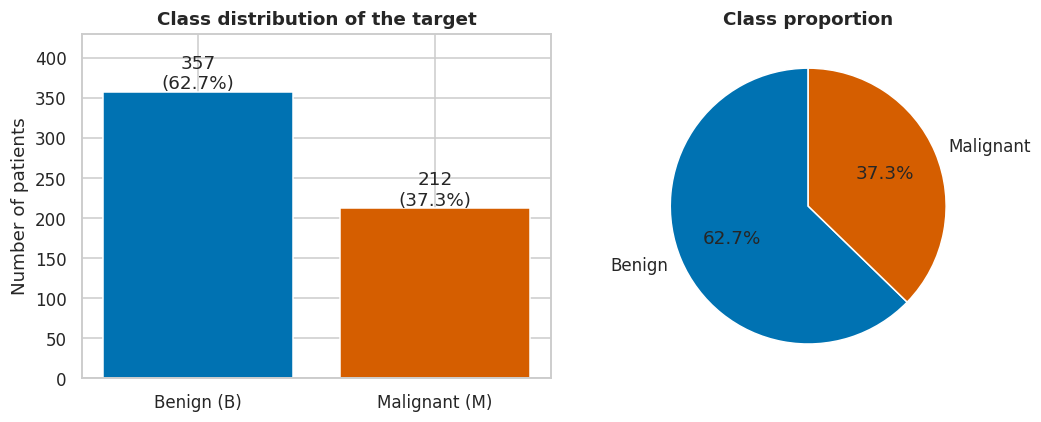

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
order = ["B", "M"]
bars = ax[0].bar(["Benign (B)", "Malignant (M)"], [cls_counts[o] for o in order], color=[PALETTE[o] for o in order])
for b_, o in zip(bars, order):
    ax[0].text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 4, f"{cls_counts[o]}\n({cls_counts[o]/len(df):.1%})", ha="center")
ax[0].set(title="Class distribution of the target", ylabel="Number of patients", ylim=(0, 430))
ax[1].pie([cls_counts[o] for o in order], labels=["Benign", "Malignant"], colors=[PALETTE[o] for o in order],
          autopct="%1.1f%%", startangle=90, wedgeprops=dict(edgecolor="white"))
ax[1].set_title("Class proportion")
finish("fig01_class_distribution.png")

### Visual 2 – Histograms with KDE (univariate distributions, split by diagnosis)

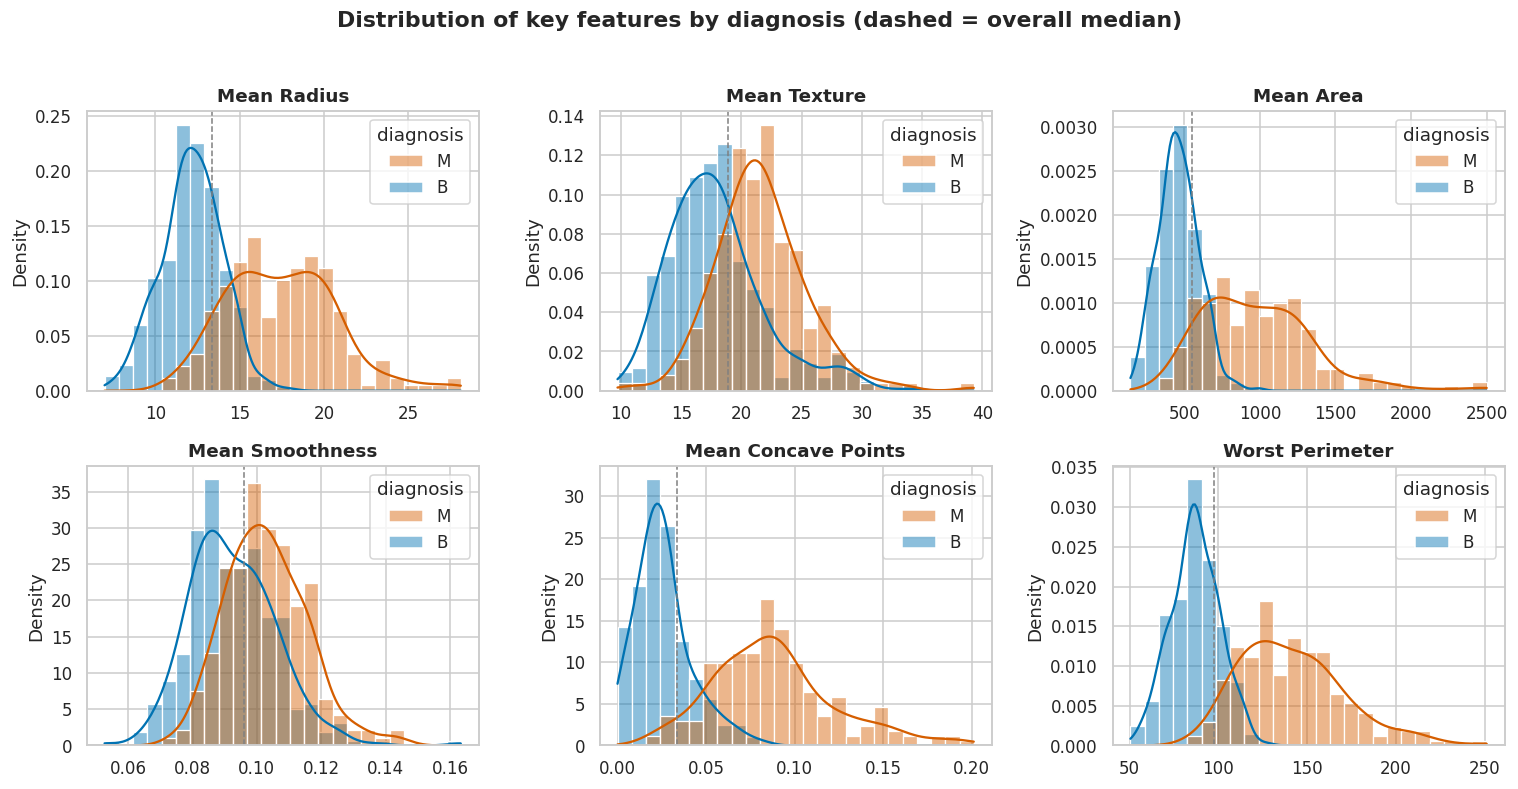

In [10]:
key6 = ["mean_radius", "mean_texture", "mean_area", "mean_smoothness", "mean_concave_points", "worst_perimeter"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), key6):
    sns.histplot(data=df, x=f, hue="diagnosis", palette=PALETTE, kde=True, stat="density", common_norm=False,
                 alpha=0.45, bins=25, ax=ax)
    ax.set_title(f.replace("_", " ").title()); ax.set_xlabel("")
    ax.axvline(df[f].median(), color="grey", ls="--", lw=1)
fig.suptitle("Distribution of key features by diagnosis (dashed = overall median)", fontweight="bold", y=1.02)
finish("fig02_histograms_kde.png")

### Visual 3 – Box plots (spread and outliers)

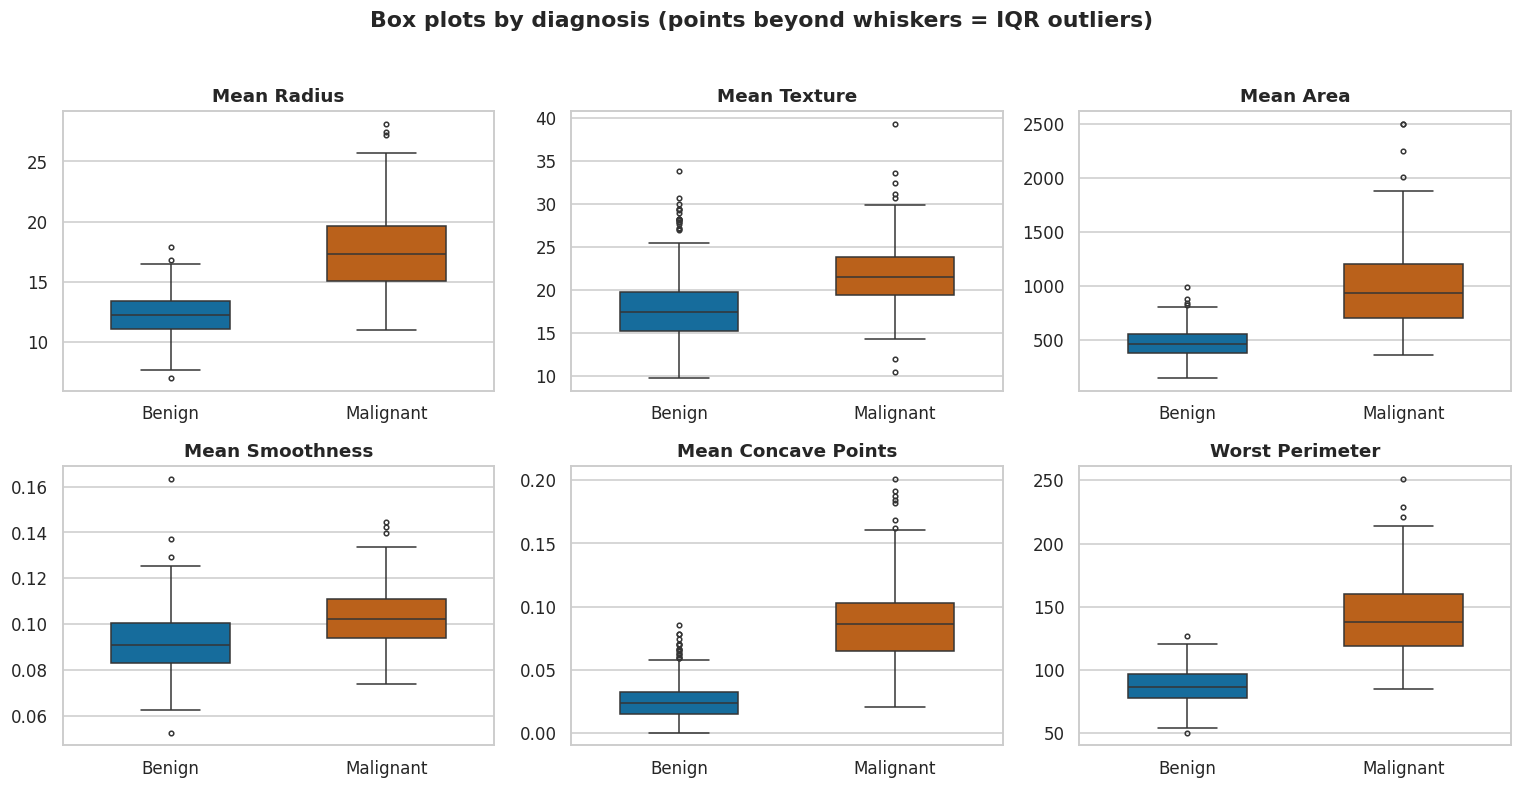

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), key6):
    sns.boxplot(data=df, x="diagnosis", y=f, order=["B", "M"], palette=PALETTE, hue="diagnosis", legend=False,
                width=0.55, fliersize=3, ax=ax)
    ax.set_title(f.replace("_", " ").title()); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Benign", "Malignant"])
fig.suptitle("Box plots by diagnosis (points beyond whiskers = IQR outliers)", fontweight="bold", y=1.02)
finish("fig03_boxplots.png")

### Visual 4 – Outlier prevalence (Tukey IQR) per feature

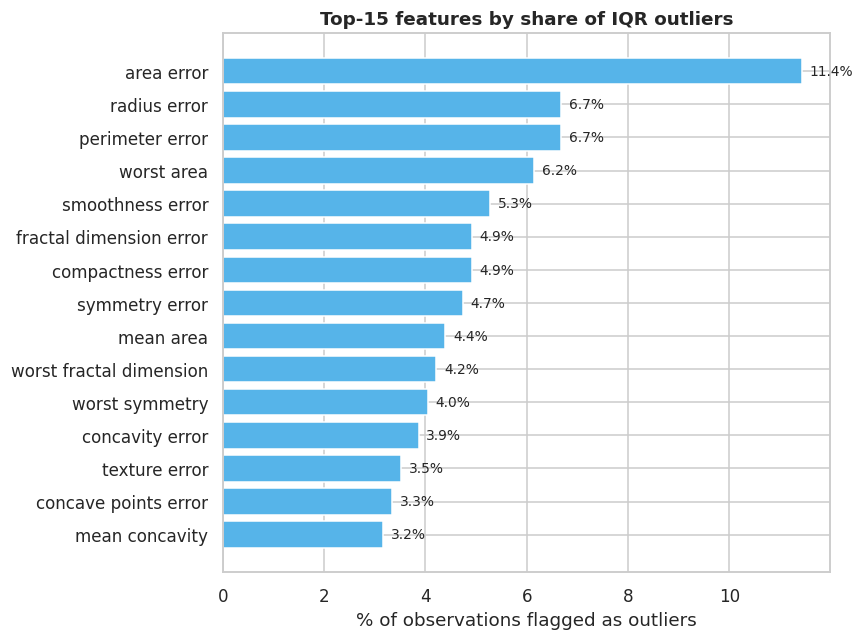

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
top_o = out_pct.head(15)[::-1]
ax.barh([i.replace("_", " ") for i in top_o.index], top_o.values, color="#56B4E9")
for i, v in enumerate(top_o.values):
    ax.text(v + 0.15, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set(title="Top-15 features by share of IQR outliers", xlabel="% of observations flagged as outliers")
finish("fig04_outlier_prevalence.png")

### Visual 5 – Correlation heat-map (multivariate relationships)

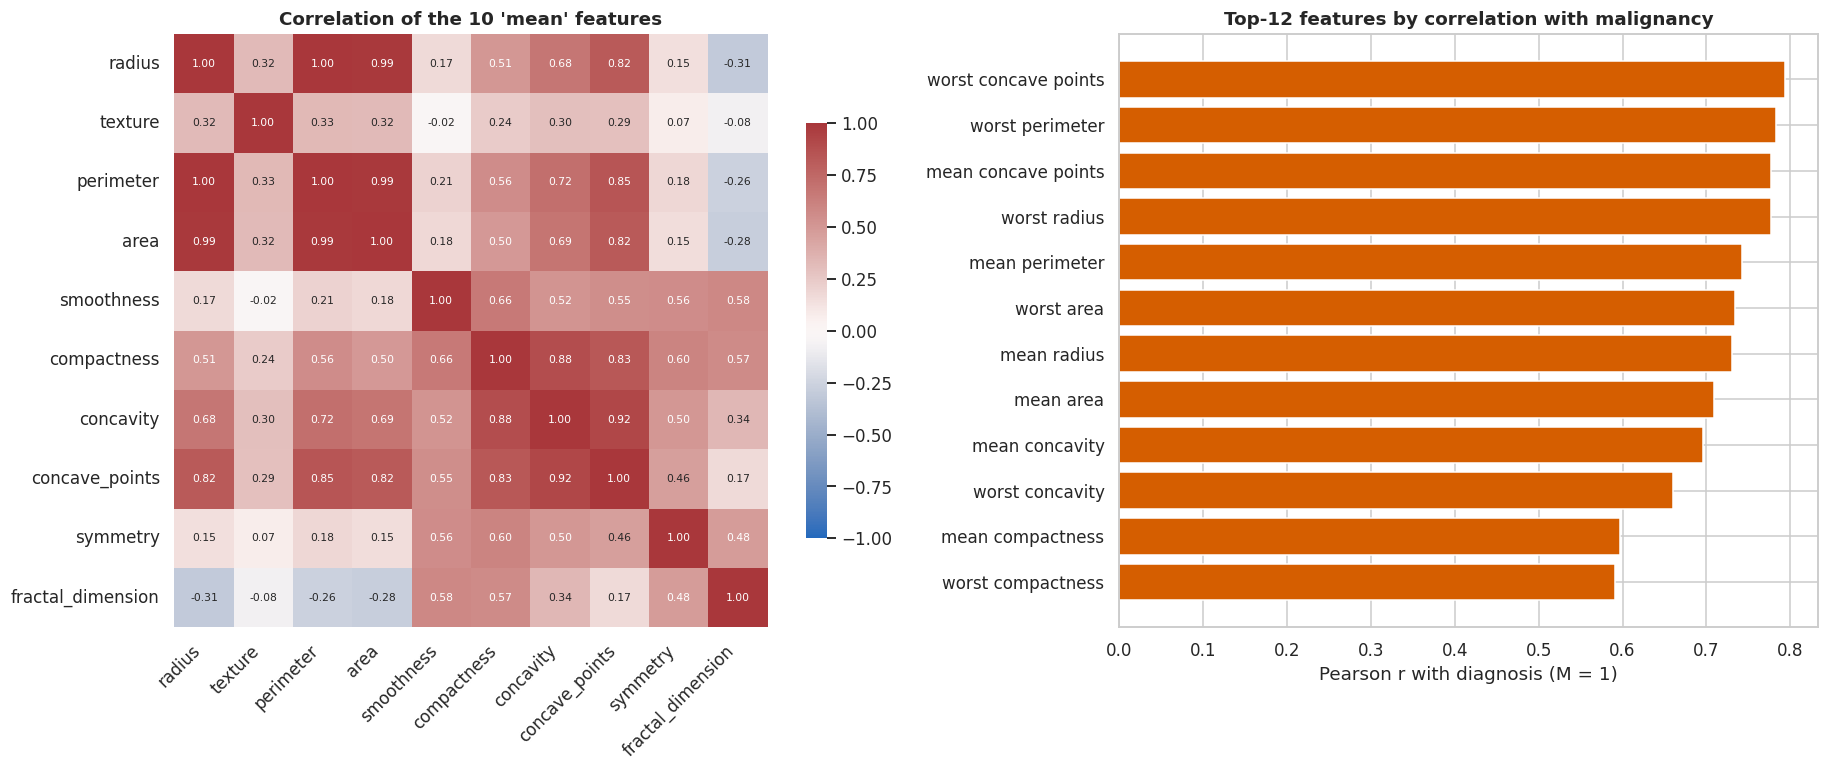

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.1, 1]})
mc = df[groups["mean"]].corr()
sns.heatmap(mc, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": .7}, annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("Correlation of the 10 'mean' features")
axes[0].set_xticklabels([t.get_text().replace("mean_", "") for t in axes[0].get_xticklabels()], rotation=45, ha="right")
axes[0].set_yticklabels([t.get_text().replace("mean_", "") for t in axes[0].get_yticklabels()], rotation=0)
tc = target_corr.head(12)[::-1]
axes[1].barh([i.replace("_", " ") for i in tc.index], tc.values, color=["#D55E00" if v > 0 else "#0072B2" for v in tc.values])
axes[1].set(title="Top-12 features by correlation with malignancy", xlabel="Pearson r with diagnosis (M = 1)")
finish("fig05_correlation_heatmap.png")

### Visual 6 – Scatter plots (bivariate relationships)

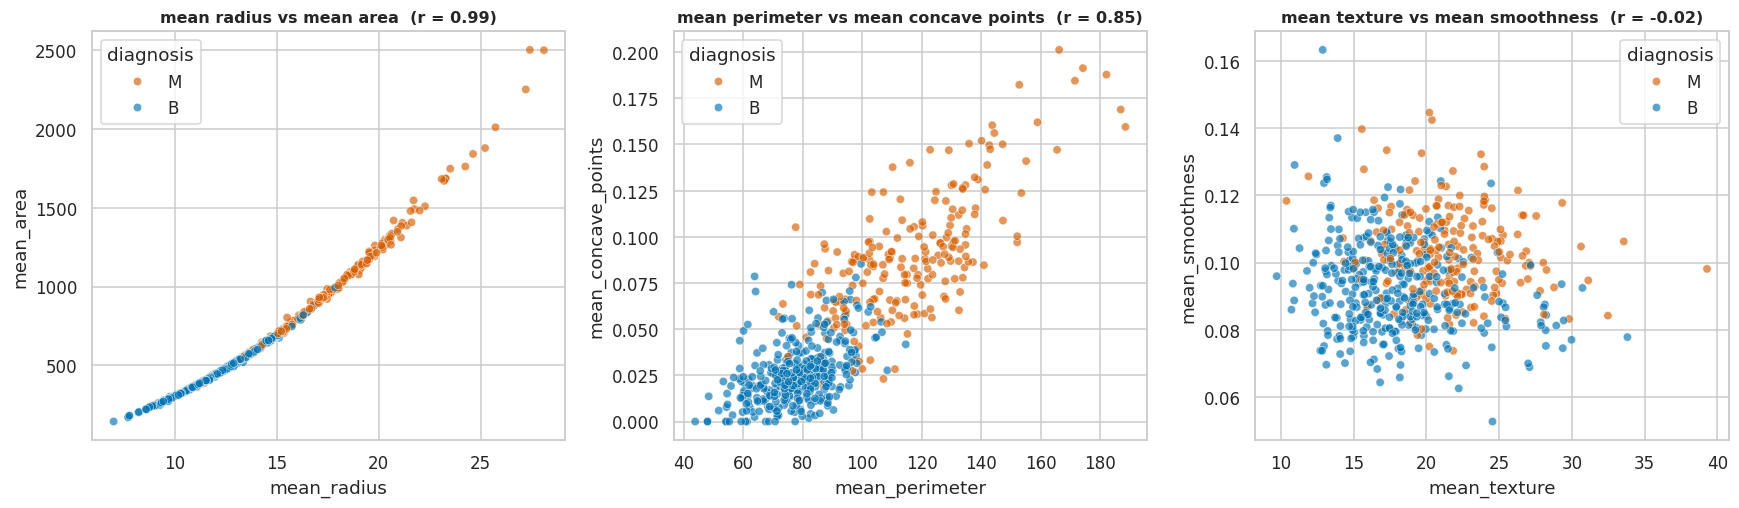

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (xf, yf) in zip(axes, [("mean_radius", "mean_area"), ("mean_perimeter", "mean_concave_points"), ("mean_texture", "mean_smoothness")]):
    sns.scatterplot(data=df, x=xf, y=yf, hue="diagnosis", palette=PALETTE, alpha=0.65, s=30, ax=ax)
    r = df[xf].corr(df[yf])
    ax.set_title(f"{xf.replace('_',' ')} vs {yf.replace('_',' ')}  (r = {r:.2f})", fontsize=10.5)
metrics["scatter_r"] = {"radius_area": round(float(df.mean_radius.corr(df.mean_area)), 3),
                        "perimeter_concave": round(float(df.mean_perimeter.corr(df.mean_concave_points)), 3),
                        "texture_smoothness": round(float(df.mean_texture.corr(df.mean_smoothness)), 3)}
finish("fig06_scatter_relationships.png")

### Visual 7 – Pair plot (multivariate view)

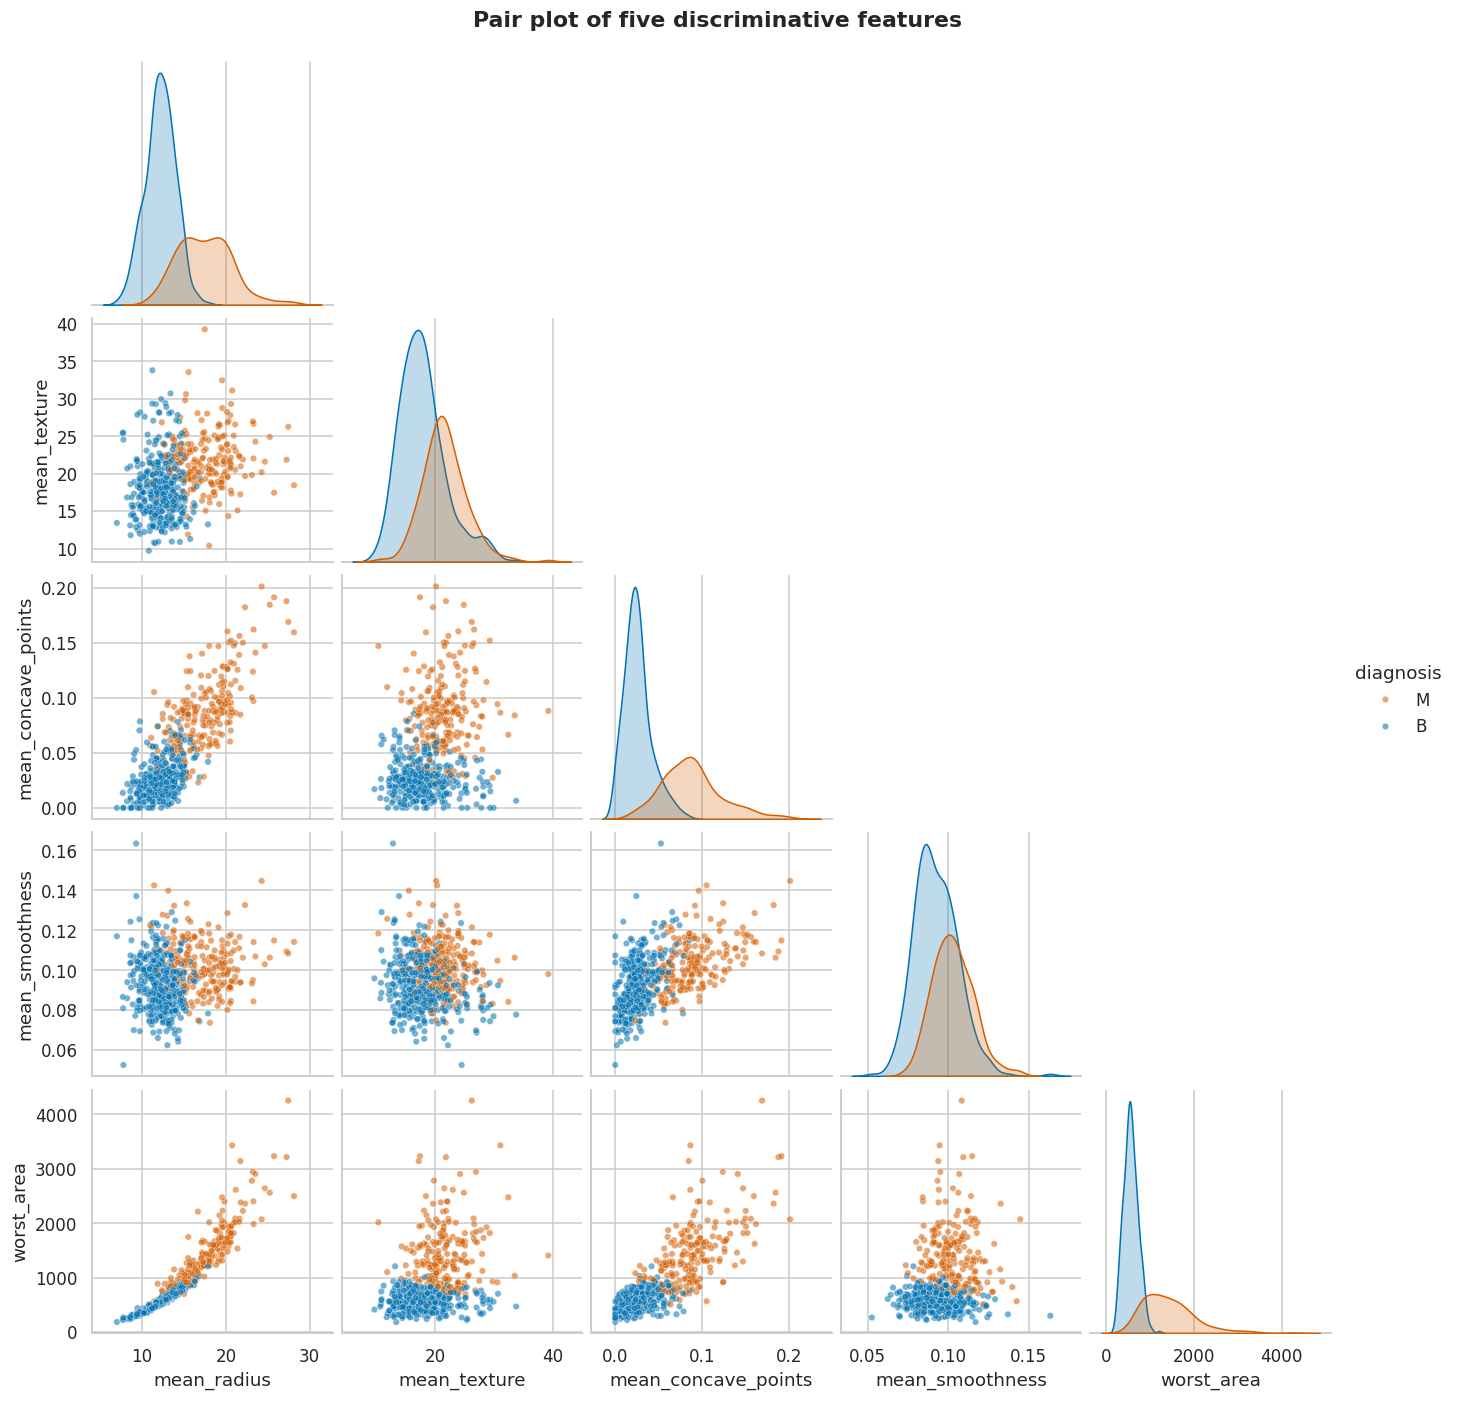

In [15]:
pp = sns.pairplot(df, vars=["mean_radius", "mean_texture", "mean_concave_points", "mean_smoothness", "worst_area"],
                  hue="diagnosis", palette=PALETTE, corner=True, plot_kws=dict(alpha=0.55, s=18), diag_kind="kde")
pp.figure.suptitle("Pair plot of five discriminative features", y=1.02, fontweight="bold")
pp.figure.savefig(FIG / "fig07_pairplot.png", dpi=130, bbox_inches="tight")
plt.show() if IN_NB else plt.close("all")

### Visual 8 – Distribution fitting: histogram + Normal/Log-normal PDF and Q-Q plots (continuous distributions)

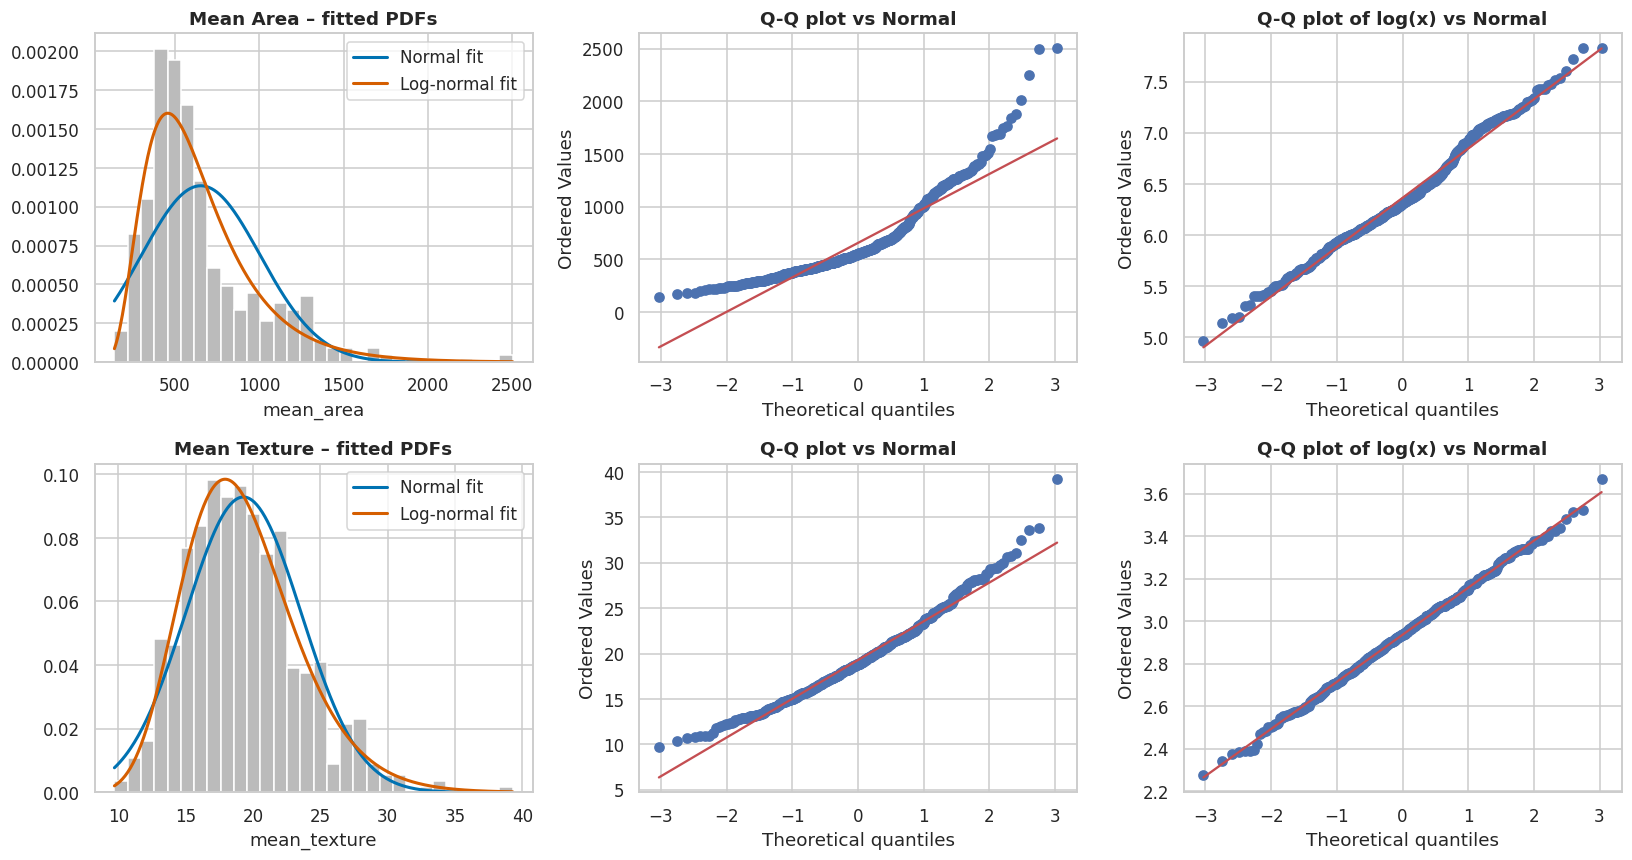

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for r_i, f in enumerate(["mean_area", "mean_texture"]):
    x = df[f].values
    mu, sd = stats.norm.fit(x); sh, lc, sc = stats.lognorm.fit(x, floc=0)
    g = np.linspace(x.min(), x.max(), 300)
    axes[r_i, 0].hist(x, bins=30, density=True, color="#BBBBBB", edgecolor="white")
    axes[r_i, 0].plot(g, stats.norm.pdf(g, mu, sd), color="#0072B2", lw=2, label="Normal fit")
    axes[r_i, 0].plot(g, stats.lognorm.pdf(g, sh, lc, sc), color="#D55E00", lw=2, label="Log-normal fit")
    axes[r_i, 0].set(title=f"{f.replace('_',' ').title()} – fitted PDFs", xlabel=f); axes[r_i, 0].legend()
    stats.probplot(x, dist="norm", plot=axes[r_i, 1]); axes[r_i, 1].set_title("Q-Q plot vs Normal")
    stats.probplot(np.log(x), dist="norm", plot=axes[r_i, 2]); axes[r_i, 2].set_title("Q-Q plot of log(x) vs Normal")
finish("fig08_distribution_fitting.png")

### Visual 9 – Discrete distribution: Binomial model of malignant cases in a random sample

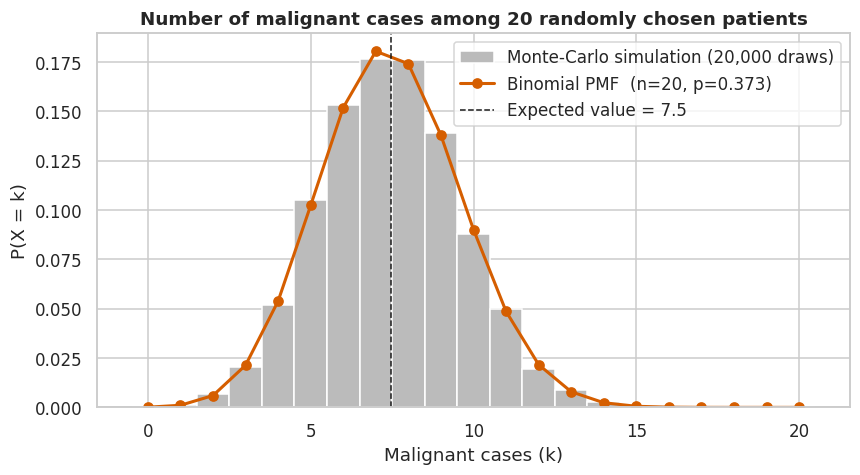

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(sim, bins=np.arange(-0.5, n_trial + 1.5, 1), density=True, color="#BBBBBB", edgecolor="white", label="Monte-Carlo simulation (20,000 draws)")
ax.plot(k, pmf, "o-", color="#D55E00", lw=2, label=f"Binomial PMF  (n={n_trial}, p={p_mal:.3f})")
ax.axvline(n_trial * p_mal, color="k", ls="--", lw=1, label=f"Expected value = {n_trial*p_mal:.1f}")
ax.set(title="Number of malignant cases among 20 randomly chosen patients", xlabel="Malignant cases (k)", ylabel="P(X = k)")
ax.legend()
finish("fig09_binomial_distribution.png")

### Visual 10 – PCA: scree plot and 2-D projection

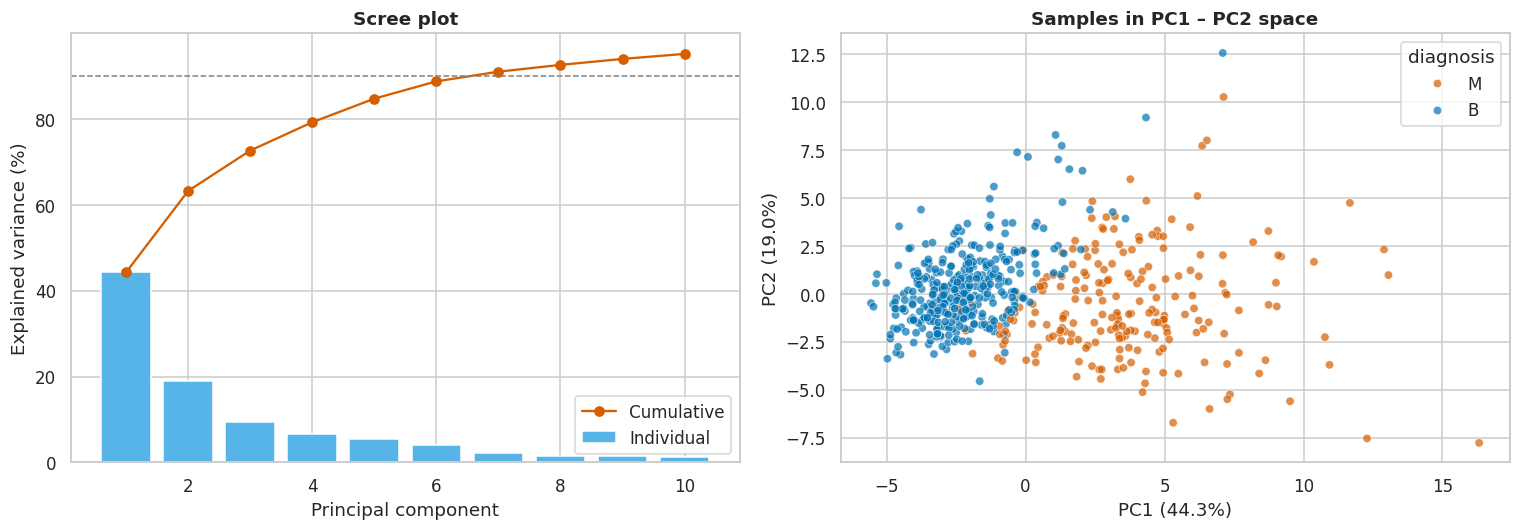

In [18]:
Xs = StandardScaler().fit_transform(df[FEATURES])
pcs = PCA(n_components=2).fit_transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, 11), pca_full.explained_variance_ratio_[:10] * 100, color="#56B4E9", label="Individual")
axes[0].plot(range(1, 11), cum[:10] * 100, "o-", color="#D55E00", label="Cumulative")
axes[0].axhline(90, color="grey", ls="--", lw=1)
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Explained variance (%)"); axes[0].legend()
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df.diagnosis, palette=PALETTE, alpha=0.7, s=30, ax=axes[1])
axes[1].set(title="Samples in PC1 – PC2 space", xlabel=f"PC1 ({metrics['pca']['pc1']:.1%})", ylabel=f"PC2 ({metrics['pca']['pc2']:.1%})")
finish("fig10_pca.png")

## STAGE 6 – REFINE (transformation, encoding, scaling, splitting)
* **Encode** target: `M → 1`, `B → 0` (malignant is the positive class).
* **Split first** (stratified 70 % train / 15 % validation / 15 % test) so that nothing learned from validation/test leaks into preprocessing.
* **Transform** the 22 highly skewed (|skew| > 1) features with a **Yeo-Johnson power transform** – a plain `log1p` was tried first
  but barely changes features whose values are ≪ 1 (e.g. `concavity_error`), so it is not suitable here.
* **Standardise** (z-score). Both the power transform and the scaler are **fitted on the training set only**.

In [19]:
y = (df["diagnosis"] == "M").astype(int).values
X = df[FEATURES].copy()
skewed_cols = skew[skew.abs() > 1].index.tolist()

# 1) stratified split of the RAW features
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

# 2) fit the transformers on TRAIN only, then apply to train / validation / test
pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(X_tr[skewed_cols])
def yj(Xdf):
    """Apply the (train-fitted) Yeo-Johnson transform to the skewed columns."""
    out = Xdf.copy(); out[skewed_cols] = pt.transform(Xdf[skewed_cols]); return out
scaler = StandardScaler().fit(yj(X_tr))
Z_tr, Z_va, Z_te = (pd.DataFrame(scaler.transform(yj(a)), columns=FEATURES) for a in (X_tr, X_va, X_te))

skew_after = yj(X).skew()
metrics["skew_mean_abs_before"] = round(float(skew.abs().mean()), 3)
metrics["skew_mean_abs_after"] = round(float(skew_after.abs().mean()), 3)
metrics["n_transformed"] = len(skewed_cols)
metrics["n_still_skewed"] = int((skew_after.abs() > 1).sum())
metrics["skew_examples"] = {c: [round(float(skew[c]), 2), round(float(skew_after[c]), 2)]
                            for c in ["area_error", "concavity_error", "fractal_dimension_error", "perimeter_error", "mean_area"]}
print(f"Mean |skewness|: {metrics['skew_mean_abs_before']} -> {metrics['skew_mean_abs_after']} "
      f"(Yeo-Johnson on {len(skewed_cols)} features; still skewed: {metrics['n_still_skewed']})")
metrics["split"] = dict(train=len(y_tr), val=len(y_va), test=len(y_te),
                        malignant_train=int(y_tr.sum()), malignant_val=int(y_va.sum()), malignant_test=int(y_te.sum()))
print(metrics["split"])
for name, Z, yy in (("train", Z_tr, y_tr), ("val", Z_va, y_va), ("test", Z_te, y_te)):
    out = Z.copy(); out["diagnosis"] = yy
    out.to_csv(PROC / f"{name}.csv", index=False)           # saved for reproducibility

Mean |skewness|: 1.74 -> 0.25 (Yeo-Johnson on 22 features; still skewed: 0)
{'train': 398, 'val': 85, 'test': 86, 'malignant_train': 148, 'malignant_val': 32, 'malignant_test': 32}


### Visual 11 – Effect of the power transform on skewness

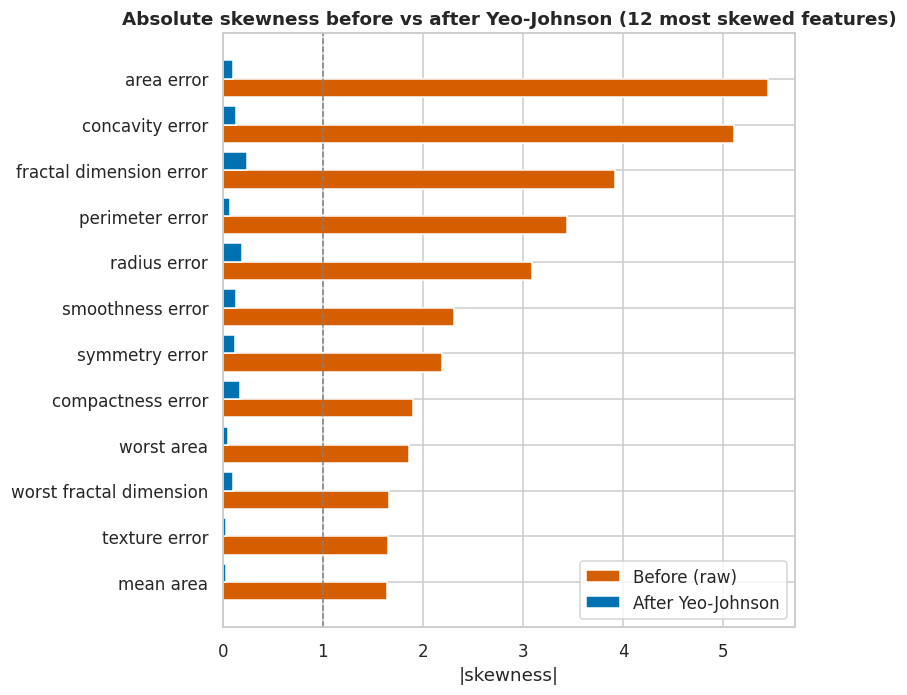

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
lab = skew.abs().sort_values(ascending=False).head(12).index
ypos = np.arange(len(lab))
ax.barh(ypos + 0.2, skew[lab].abs().values, height=0.4, color="#D55E00", label="Before (raw)")
ax.barh(ypos - 0.2, skew_after[lab].abs().values, height=0.4, color="#0072B2", label="After Yeo-Johnson")
ax.set_yticks(ypos); ax.set_yticklabels([l.replace("_", " ") for l in lab]); ax.invert_yaxis()
ax.axvline(1, color="grey", ls="--", lw=1); ax.legend()
ax.set(title="Absolute skewness before vs after Yeo-Johnson (12 most skewed features)", xlabel="|skewness|")
finish("fig11_skewness_before_after.png")

## STAGE 7 – INTERACT (self-contained interactive explorer)
Creates `interactive/scatter_explorer.html` – open it in any browser: choose any two features, toggle classes, hover to inspect a patient.

In [21]:
payload = {"cols": FEATURES, "diag": df["diagnosis"].tolist(),
           "rows": df[FEATURES].round(4).values.tolist()}
html = r"""<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>WDBC Interactive Feature Explorer</title>
<style>
 body{font-family:system-ui,Segoe UI,Arial,sans-serif;margin:20px;color:#222;max-width:900px}
 h1{font-size:20px;margin:0 0 4px} p.sub{margin:0 0 14px;color:#555;font-size:14px}
 .controls{display:flex;gap:16px;flex-wrap:wrap;align-items:center;margin-bottom:10px;font-size:14px}
 select{padding:4px 6px} svg{background:#fff;border:1px solid #ddd;border-radius:6px;max-width:100%}
 #tip{position:fixed;pointer-events:none;background:#222;color:#fff;font-size:12px;padding:6px 8px;border-radius:4px;display:none;line-height:1.4}
 .dot{opacity:.65;stroke:#fff;stroke-width:.6} .dot:hover{opacity:1;stroke:#000;stroke-width:1.5}
 #stats{font-size:14px;margin-top:8px}
</style></head><body>
<h1>Breast Cancer Wisconsin (Diagnostic) – Interactive Feature Explorer</h1>
<p class="sub">Pick any two of the 30 features, filter by diagnosis and hover over a point to inspect it. Stage 7 (Interact) of the visualization pipeline.</p>
<div class="controls">
 <label>X-axis: <select id="xs"></select></label><label>Y-axis: <select id="ys"></select></label>
 <label><input type="checkbox" id="cb" checked> <span style="color:#0072B2">&#9679;</span> Benign</label>
 <label><input type="checkbox" id="cm" checked> <span style="color:#D55E00">&#9679;</span> Malignant</label>
</div>
<svg id="plot" width="860" height="520" viewBox="0 0 860 520"></svg>
<div id="stats"></div><div id="tip"></div>
<script>
const D = __DATA__;
const COL = {B:"#0072B2", M:"#D55E00"}, W=860, H=520, m={l:70,r:20,t:20,b:55};
const xs=document.getElementById("xs"), ys=document.getElementById("ys"), tip=document.getElementById("tip");
D.cols.forEach((c,i)=>{xs.add(new Option(c.replace(/_/g," "),i)); ys.add(new Option(c.replace(/_/g," "),i));});
xs.value=0; ys.value=3;
function ticks(lo,hi,n){const s=(hi-lo)/n, out=[]; for(let i=0;i<=n;i++) out.push(lo+i*s); return out;}
function fmt(v){return Math.abs(v)>=100? v.toFixed(0): Math.abs(v)>=1? v.toFixed(2): v.toPrecision(2);}
function pearson(a,b){const n=a.length; if(n<3) return NaN; const ma=a.reduce((s,v)=>s+v,0)/n, mb=b.reduce((s,v)=>s+v,0)/n;
 let sab=0,saa=0,sbb=0; for(let i=0;i<n;i++){sab+=(a[i]-ma)*(b[i]-mb); saa+=(a[i]-ma)**2; sbb+=(b[i]-mb)**2;} return sab/Math.sqrt(saa*sbb);}
function draw(){
 const xi=+xs.value, yi=+ys.value, showB=document.getElementById("cb").checked, showM=document.getElementById("cm").checked;
 const X=D.rows.map(r=>r[xi]), Y=D.rows.map(r=>r[yi]);
 const x0=Math.min(...X), x1=Math.max(...X), y0=Math.min(...Y), y1=Math.max(...Y);
 const px=(x1-x0)*.04||1, py=(y1-y0)*.04||1;
 const sx=v=>m.l+(v-(x0-px))/((x1+px)-(x0-px))*(W-m.l-m.r), sy=v=>H-m.b-(v-(y0-py))/((y1+py)-(y0-py))*(H-m.t-m.b);
 let s="";
 ticks(x0,x1,6).forEach(t=>{s+=`<line x1="${sx(t)}" x2="${sx(t)}" y1="${m.t}" y2="${H-m.b}" stroke="#eee"/><text x="${sx(t)}" y="${H-m.b+18}" font-size="11" text-anchor="middle">${fmt(t)}</text>`;});
 ticks(y0,y1,6).forEach(t=>{s+=`<line y1="${sy(t)}" y2="${sy(t)}" x1="${m.l}" x2="${W-m.r}" stroke="#eee"/><text y="${sy(t)+4}" x="${m.l-8}" font-size="11" text-anchor="end">${fmt(t)}</text>`;});
 s+=`<line x1="${m.l}" x2="${W-m.r}" y1="${H-m.b}" y2="${H-m.b}" stroke="#444"/><line x1="${m.l}" x2="${m.l}" y1="${m.t}" y2="${H-m.b}" stroke="#444"/>`;
 s+=`<text x="${(W+m.l)/2}" y="${H-12}" font-size="13" text-anchor="middle" font-weight="600">${D.cols[xi].replace(/_/g," ")}</text>`;
 s+=`<text transform="translate(18,${(H-m.b+m.t)/2}) rotate(-90)" font-size="13" text-anchor="middle" font-weight="600">${D.cols[yi].replace(/_/g," ")}</text>`;
 const vx=[],vy=[];
 D.rows.forEach((r,i)=>{const d=D.diag[i]; if((d==="B"&&!showB)||(d==="M"&&!showM)) return; vx.push(r[xi]); vy.push(r[yi]);
  s+=`<circle class="dot" cx="${sx(r[xi])}" cy="${sy(r[yi])}" r="4.2" fill="${COL[d]}" data-i="${i}"/>`;});
 document.getElementById("plot").innerHTML=s;
 const r=pearson(vx,vy);
 document.getElementById("stats").innerHTML=`Showing <b>${vx.length}</b> patients &nbsp;|&nbsp; Pearson r (visible points) = <b>${isNaN(r)?"n/a":r.toFixed(3)}</b>`;
}
document.getElementById("plot").addEventListener("mousemove",e=>{
 const t=e.target; if(!t.dataset||t.dataset.i===undefined){tip.style.display="none";return;}
 const i=+t.dataset.i, xi=+xs.value, yi=+ys.value;
 tip.innerHTML=`<b>Patient #${i}</b> – ${D.diag[i]==="M"?"Malignant":"Benign"}<br>${D.cols[xi].replace(/_/g," ")}: ${D.rows[i][xi]}<br>${D.cols[yi].replace(/_/g," ")}: ${D.rows[i][yi]}`;
 tip.style.display="block"; tip.style.left=(e.clientX+14)+"px"; tip.style.top=(e.clientY+14)+"px";});
document.getElementById("plot").addEventListener("mouseleave",()=>tip.style.display="none");
[xs,ys,document.getElementById("cb"),document.getElementById("cm")].forEach(el=>el.addEventListener("change",draw));
draw();
</script></body></html>"""
(INTER / "scatter_explorer.html").write_text(html.replace("__DATA__", json.dumps(payload, separators=(",", ":"))), encoding="utf-8")
print("Interactive explorer written to", (INTER / "scatter_explorer.html").relative_to(ROOT))

Interactive explorer written to interactive/scatter_explorer.html


## FEATURE ANALYSIS & FEATURE IMPORTANCE
Three complementary views: Random-Forest (impurity) importance, Mutual Information, and permutation importance of the
final MLP (the last one is computed after the model is trained – see below).

In [22]:
rf = RandomForestClassifier(n_estimators=300, random_state=SEED).fit(Z_tr, y_tr)
imp_rf = pd.Series(rf.feature_importances_, index=FEATURES)
imp_mi = pd.Series(mutual_info_classif(Z_tr, y_tr, random_state=SEED), index=FEATURES)
print("Top-5 RF importance :", imp_rf.sort_values(ascending=False).head(5).round(3).to_dict())
print("Top-5 mutual info   :", imp_mi.sort_values(ascending=False).head(5).round(3).to_dict())

Top-5 RF importance : {'worst_perimeter': 0.141, 'worst_area': 0.139, 'mean_concave_points': 0.108, 'worst_concave_points': 0.091, 'worst_radius': 0.087}
Top-5 mutual info   : {'worst_perimeter': 0.453, 'worst_radius': 0.444, 'worst_area': 0.441, 'mean_concave_points': 0.436, 'worst_concave_points': 0.414}


## DEEP-LEARNING MODEL – Multi-Layer Perceptron (feed-forward neural network)
* Input: 30 standardised features → ≥ 2 hidden layers (ReLU) → 1 sigmoid output (P(malignant)).
* Optimiser: **Adam**, loss: binary cross-entropy (log-loss), mini-batch size 32, L2 regularisation (`alpha`).
* Training is done **epoch by epoch** so that loss/accuracy curves on train *and* validation sets can be recorded.
* **Early stopping** on validation loss (patience = 20) – the weights of the best epoch are restored.

In [23]:
def train_mlp(hidden, alpha, lr, Xtr, ytr, Xva, yva, max_epochs=200, patience=20, seed=SEED):
    """Train an MLP epoch-by-epoch; return (best_model, history, best_epoch)."""
    clf = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam", alpha=alpha,
                        learning_rate_init=lr, batch_size=32, random_state=seed)
    hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
    best_loss, best_clf, best_ep, wait = np.inf, None, 0, 0
    for ep in range(1, max_epochs + 1):
        clf.partial_fit(Xtr, ytr, classes=[0, 1])            # one pass over the training data = one epoch
        p_tr, p_va = clf.predict_proba(Xtr)[:, 1], clf.predict_proba(Xva)[:, 1]
        hist["loss"].append(log_loss(ytr, p_tr)); hist["val_loss"].append(log_loss(yva, p_va))
        hist["acc"].append(accuracy_score(ytr, p_tr > .5)); hist["val_acc"].append(accuracy_score(yva, p_va > .5))
        if hist["val_loss"][-1] < best_loss - 1e-5:
            best_loss, best_clf, best_ep, wait = hist["val_loss"][-1], copy.deepcopy(clf), ep, 0
        else:
            wait += 1
            if wait >= patience:
                break
    return best_clf, hist, best_ep

### Basic hyper-parameter tuning (grid search on the **validation** set)
Grid: hidden-layer architecture (all ≥ 2 hidden layers, i.e. a *deep* network) × L2 penalty (`alpha`) × learning rate
= 4 × 2 × 3 = 24 configurations. Selection criterion: highest validation accuracy, ties broken by lowest validation loss.

In [24]:
LRS = [2.5e-4, 5e-4, 1e-3]      # lr >= 5e-3 was tried first: validation loss bottomed out after only ~2 epochs (unstable), so the grid is centred on gentler rates
HIDDEN = [(32, 16), (64, 32), (64, 32, 16), (128, 64, 32)]
grid = [(h, a, lr) for h in HIDDEN for a in [1e-4, 1e-2] for lr in LRS]
tune = []
for h, a, lr in grid:
    mdl, hs, be = train_mlp(h, a, lr, Z_tr, y_tr, Z_va, y_va)
    pv = mdl.predict_proba(Z_va)[:, 1]
    tune.append(dict(hidden=str(h), alpha=a, lr=lr, best_epoch=be, val_loss=log_loss(y_va, pv),
                     val_acc=accuracy_score(y_va, pv > .5), val_auc=roc_auc_score(y_va, pv)))
tune_df = pd.DataFrame(tune).sort_values(["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True)
tune_df.to_csv(OUT / "hyperparameter_tuning_results.csv", index=False)
display(tune_df.head(8).round(4))
best = tune_df.iloc[0]
BEST = dict(hidden=eval(best.hidden), alpha=float(best.alpha), lr=float(best.lr))
print("\nBest configuration:", BEST)
metrics["tuning"] = dict(n_configs=len(grid), best=dict(hidden=best.hidden, alpha=float(best.alpha), lr=float(best.lr),
                         best_epoch=int(best.best_epoch), val_acc=round(float(best.val_acc), 4), val_loss=round(float(best.val_loss), 4)),
                         worst_val_acc=round(float(tune_df.val_acc.min()), 4), top_table=tune_df.head(5).round(4).to_dict("records"))

         hidden   alpha      lr  best_epoch  val_loss  val_acc  val_auc
0  (64, 32, 16)  0.0100  0.0010          12    0.0595   0.9882   0.9988
1  (64, 32, 16)  0.0001  0.0010          12    0.0595   0.9882   0.9988
2      (64, 32)  0.0100  0.0010          17    0.0642   0.9882   0.9959
3      (64, 32)  0.0001  0.0010          17    0.0645   0.9882   0.9959
4      (64, 32)  0.0100  0.0005          34    0.0652   0.9882   0.9959
5      (64, 32)  0.0100  0.0002          67    0.0652   0.9882   0.9959
6      (64, 32)  0.0001  0.0005          34    0.0654   0.9882   0.9959
7      (64, 32)  0.0001  0.0002          67    0.0657   0.9882   0.9959

Best configuration: {'hidden': (64, 32, 16), 'alpha': 0.01, 'lr': 0.001}


### Visual 12 – Hyper-parameter tuning heat-map

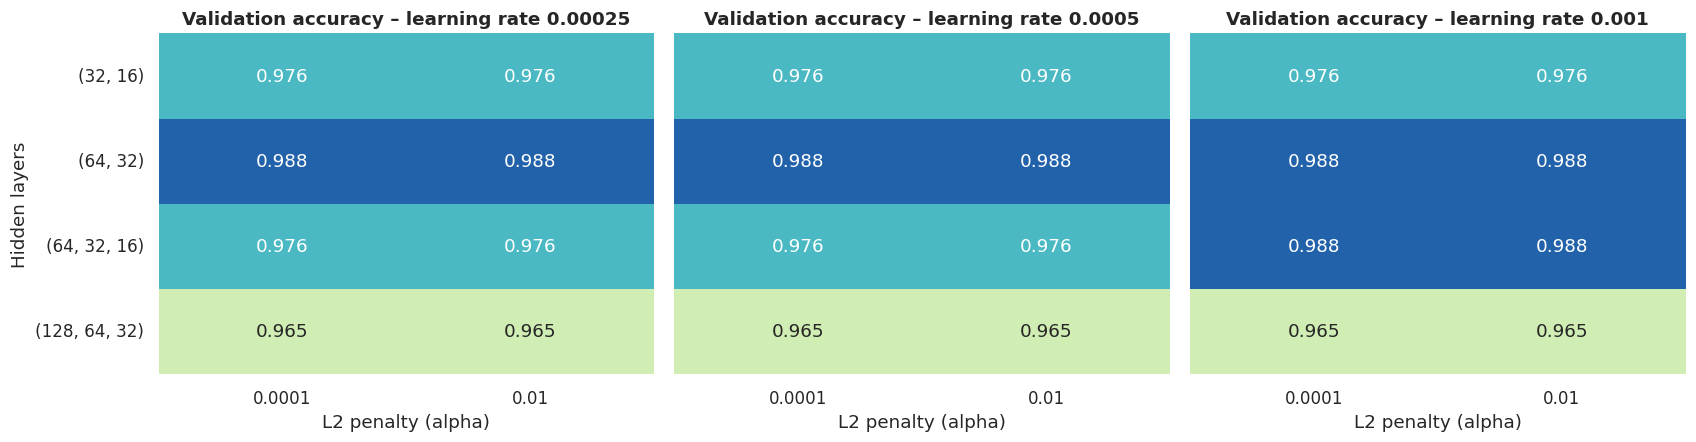

In [25]:
fig, axes = plt.subplots(1, len(LRS), figsize=(5.2 * len(LRS), 4.2))
for i_, (ax, lr) in enumerate(zip(axes, LRS)):
    pv_ = tune_df[tune_df.lr == lr].pivot(index="hidden", columns="alpha", values="val_acc").reindex([str(h) for h in HIDDEN])
    sns.heatmap(pv_, annot=True, fmt=".3f", cmap="YlGnBu", vmin=tune_df.val_acc.min() - .01, vmax=1, cbar=False, ax=ax)
    ax.set(title=f"Validation accuracy – learning rate {lr}", xlabel="L2 penalty (alpha)", ylabel="Hidden layers" if i_ == 0 else "")
    ax.tick_params(axis="y", rotation=0)
    if i_ > 0:
        ax.set_yticklabels([])
finish("fig12_hyperparameter_tuning.png")

### Train the final model with the best configuration

In [26]:
mlp, hist, best_ep = train_mlp(BEST["hidden"], BEST["alpha"], BEST["lr"], Z_tr, y_tr, Z_va, y_va)
n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print(f"Architecture: 30 -> {' -> '.join(map(str, BEST['hidden']))} -> 1 | trainable parameters = {n_params:,}")
print(f"Epochs run = {len(hist['loss'])}, best epoch (restored) = {best_ep}")
metrics["model"] = dict(hidden=str(BEST["hidden"]), n_params=int(n_params), epochs_run=len(hist["loss"]), best_epoch=int(best_ep),
                        alpha=BEST["alpha"], lr=BEST["lr"], batch_size=32, optimizer="Adam", activation="ReLU (hidden) / sigmoid (output)",
                        patience=20, max_epochs=200)

Architecture: 30 -> 64 -> 32 -> 16 -> 1 | trainable parameters = 4,609
Epochs run = 32, best epoch (restored) = 12


## MODEL EVALUATION VISUALISATIONS
### Visual 13 – Loss vs Epoch and Accuracy vs Epoch

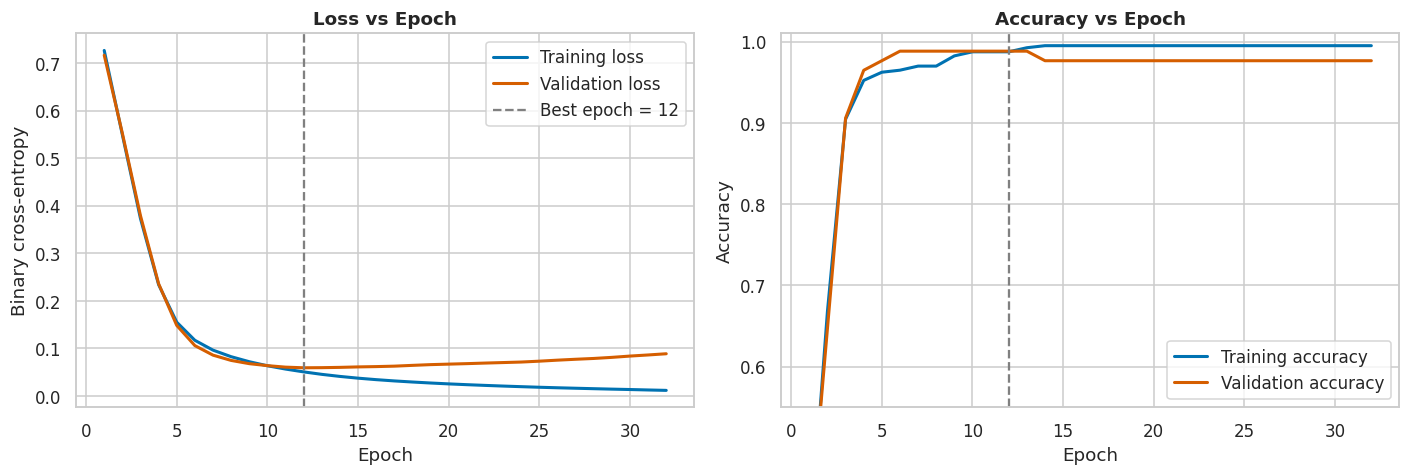

In [27]:
ep = np.arange(1, len(hist["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ep, hist["loss"], color="#0072B2", lw=2, label="Training loss")
axes[0].plot(ep, hist["val_loss"], color="#D55E00", lw=2, label="Validation loss")
axes[0].axvline(best_ep, color="grey", ls="--", label=f"Best epoch = {best_ep}")
axes[0].set(title="Loss vs Epoch", xlabel="Epoch", ylabel="Binary cross-entropy"); axes[0].legend()
axes[1].plot(ep, hist["acc"], color="#0072B2", lw=2, label="Training accuracy")
axes[1].plot(ep, hist["val_acc"], color="#D55E00", lw=2, label="Validation accuracy")
axes[1].axvline(best_ep, color="grey", ls="--")
axes[1].set(title="Accuracy vs Epoch", xlabel="Epoch", ylabel="Accuracy", ylim=(0.55, 1.01)); axes[1].legend(loc="lower right")
finish("fig13_loss_accuracy_curves.png")

In [28]:
# ---- Test-set evaluation (the test set is used ONCE, only now) ----
def evaluate(name, proba, y_true, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return dict(model=name, accuracy=accuracy_score(y_true, pred), precision=precision_score(y_true, pred),
                recall=recall_score(y_true, pred), specificity=tn / (tn + fp), f1=f1_score(y_true, pred),
                auc=roc_auc_score(y_true, proba), avg_precision=average_precision_score(y_true, proba),
                log_loss=log_loss(y_true, proba), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

p_mlp = mlp.predict_proba(Z_te)[:, 1]
lr_base = LogisticRegression(max_iter=2000, random_state=SEED).fit(Z_tr, y_tr)
p_lr, p_rf = lr_base.predict_proba(Z_te)[:, 1], rf.predict_proba(Z_te)[:, 1]
results = pd.DataFrame([evaluate("MLP (deep NN)", p_mlp, y_te), evaluate("Logistic Regression", p_lr, y_te),
                        evaluate("Random Forest", p_rf, y_te)])
results.to_csv(OUT / "test_set_results.csv", index=False)
display(results.round(4))
metrics["test_results"] = results.round(4).to_dict("records")

# 5-fold stratified CV on train+val: the power transform + scaler sit INSIDE the pipeline (re-fitted per fold -> no leakage)
X_trva, y_trva = pd.concat([X_tr, X_va]), np.concatenate([y_tr, y_va])
skew_idx = [FEATURES.index(c) for c in skewed_cols]
cv_pipe = make_pipeline(ColumnTransformer([("yj", PowerTransformer(standardize=False), skew_idx)], remainder="passthrough"),
                        StandardScaler(),
                        MLPClassifier(hidden_layer_sizes=BEST["hidden"], alpha=BEST["alpha"], learning_rate_init=BEST["lr"],
                                      batch_size=32, max_iter=max(best_ep, 30), random_state=SEED))
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_acc = cross_val_score(cv_pipe, X_trva, y_trva, cv=cv, scoring="accuracy")
cv_auc = cross_val_score(cv_pipe, X_trva, y_trva, cv=cv, scoring="roc_auc")
metrics["cv"] = dict(acc_mean=round(float(cv_acc.mean()), 4), acc_std=round(float(cv_acc.std()), 4),
                     auc_mean=round(float(cv_auc.mean()), 4), auc_std=round(float(cv_auc.std()), 4))
print("5-fold CV  accuracy = %.4f ± %.4f | AUC = %.4f ± %.4f" % (cv_acc.mean(), cv_acc.std(), cv_auc.mean(), cv_auc.std()))

                 model  accuracy  precision  recall  specificity      f1     auc  avg_precision  log_loss  tn  fp  fn  tp
0        MLP (deep NN)    0.9884     1.0000  0.9688       1.0000  0.9841  1.0000         1.0000    0.0391  54   0   1  31
1  Logistic Regression    0.9767     0.9688  0.9688       0.9815  0.9688  0.9988         0.9981    0.0462  53   1   1  31
2        Random Forest    0.9884     1.0000  0.9688       1.0000  0.9841  0.9986         0.9973    0.0822  54   0   1  31
5-fold CV  accuracy = 0.9649 ± 0.0296 | AUC = 0.9921 ± 0.0058


### Visual 14 – Confusion matrix (test set)

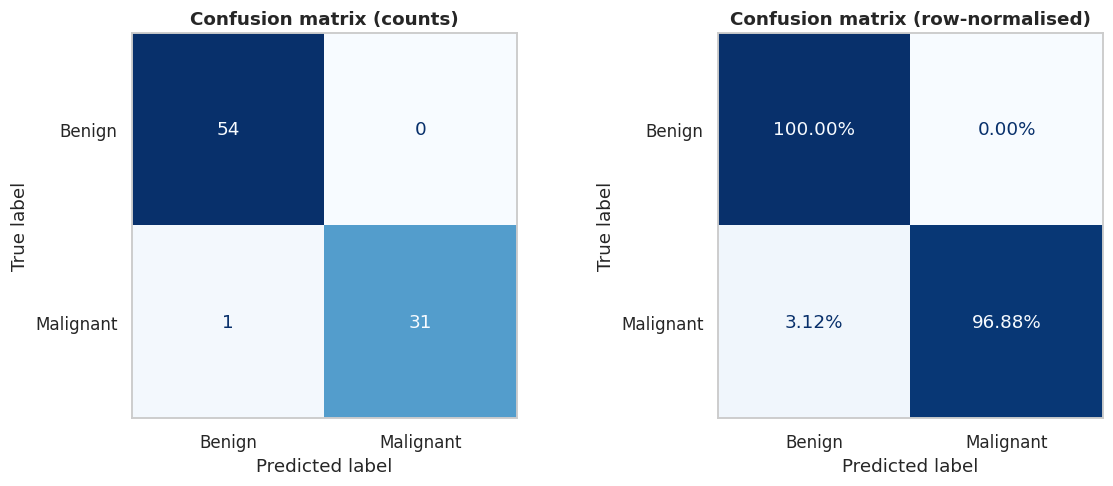

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
cm = confusion_matrix(y_te, (p_mlp >= .5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Confusion matrix (counts)"); axes[0].grid(False)
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=["Benign", "Malignant"]).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2%")
axes[1].set_title("Confusion matrix (row-normalised)"); axes[1].grid(False)
finish("fig14_confusion_matrix.png")

### Visual 15 – ROC curve with AUC, and Precision–Recall curve

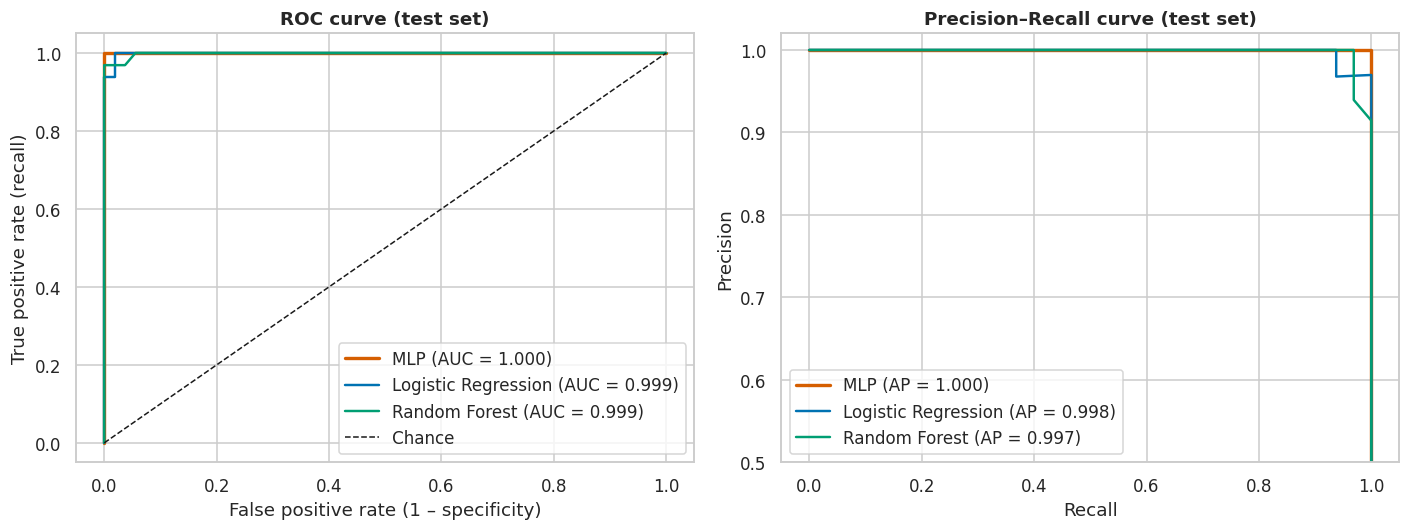

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p_, c in (("MLP", p_mlp, "#D55E00"), ("Logistic Regression", p_lr, "#0072B2"), ("Random Forest", p_rf, "#009E73")):
    fpr, tpr, _ = roc_curve(y_te, p_)
    axes[0].plot(fpr, tpr, lw=2.2 if name == "MLP" else 1.6, color=c, label=f"{name} (AUC = {roc_auc_score(y_te, p_):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p_)
    axes[1].plot(rc, pr, lw=2.2 if name == "MLP" else 1.6, color=c, label=f"{name} (AP = {average_precision_score(y_te, p_):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
axes[0].set(title="ROC curve (test set)", xlabel="False positive rate (1 – specificity)", ylabel="True positive rate (recall)"); axes[0].legend(loc="lower right")
axes[1].set(title="Precision–Recall curve (test set)", xlabel="Recall", ylabel="Precision", ylim=(0.5, 1.02)); axes[1].legend(loc="lower left")
finish("fig15_roc_pr_curves.png")

### Visual 16 – Error analysis: predicted-probability distribution and residuals

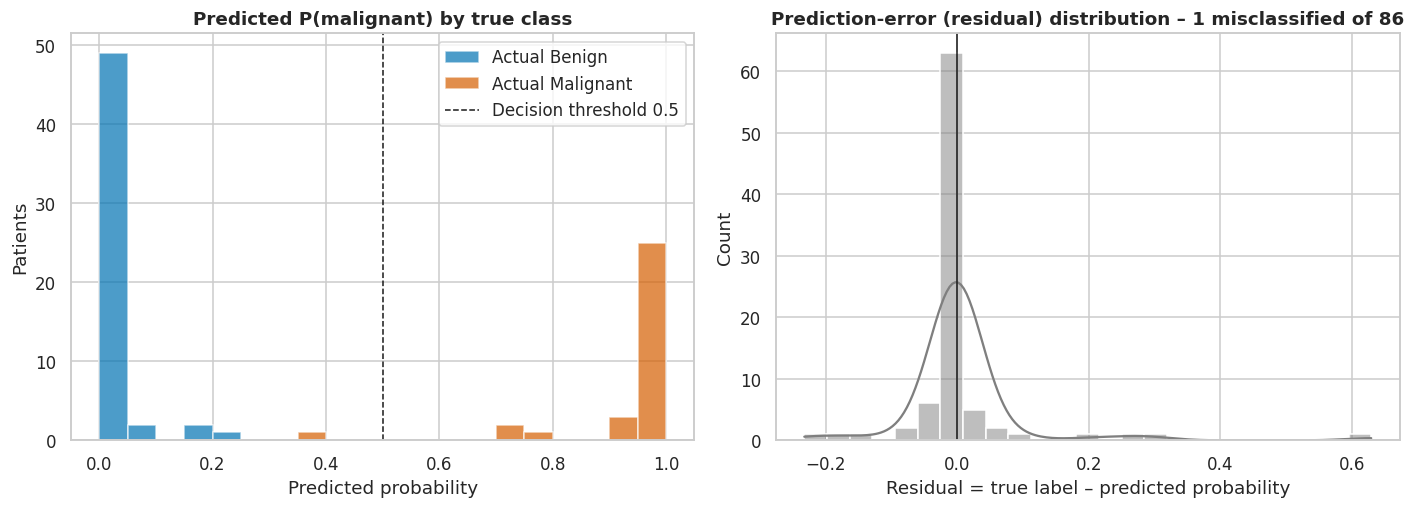

In [31]:
resid = y_te - p_mlp                       # signed error (true label minus predicted probability)
wrong = (p_mlp >= .5).astype(int) != y_te
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(p_mlp[y_te == 0], bins=20, range=(0, 1), alpha=.7, color=PALETTE["B"], label="Actual Benign")
axes[0].hist(p_mlp[y_te == 1], bins=20, range=(0, 1), alpha=.7, color=PALETTE["M"], label="Actual Malignant")
axes[0].axvline(.5, color="k", ls="--", lw=1, label="Decision threshold 0.5")
axes[0].set(title="Predicted P(malignant) by true class", xlabel="Predicted probability", ylabel="Patients"); axes[0].legend()
sns.histplot(resid, bins=25, kde=True, color="#7f7f7f", ax=axes[1])
axes[1].axvline(0, color="k", lw=1)
axes[1].set(title=f"Prediction-error (residual) distribution – {int(wrong.sum())} misclassified of {len(y_te)}",
            xlabel="Residual = true label – predicted probability")
finish("fig16_error_distribution.png")
metrics["error"] = dict(n_wrong=int(wrong.sum()), resid_mean=round(float(resid.mean()), 4), resid_sd=round(float(resid.std()), 4),
                        wrong_probs=[round(float(v), 3) for v in p_mlp[wrong]], wrong_truth=[int(v) for v in y_te[wrong]],
                        share_confident=round(float(((p_mlp < .05) | (p_mlp > .95)).mean()), 3))

### Visual 17 – Feature importance (RF, mutual information, permutation importance of the MLP)

{'rf': {'worst_perimeter': 0.141, 'worst_area': 0.139, 'mean_concave_points': 0.108, 'worst_concave_points': 0.091, 'worst_radius': 0.087}, 'mi': {'worst_perimeter': 0.453, 'worst_radius': 0.444, 'worst_area': 0.441, 'mean_concave_points': 0.436, 'worst_concave_points': 0.414}, 'perm': {'worst_concavity': 0.0447, 'mean_texture': 0.0295, 'mean_symmetry': 0.0258, 'worst_texture': 0.0248, 'mean_concavity': 0.0246}}


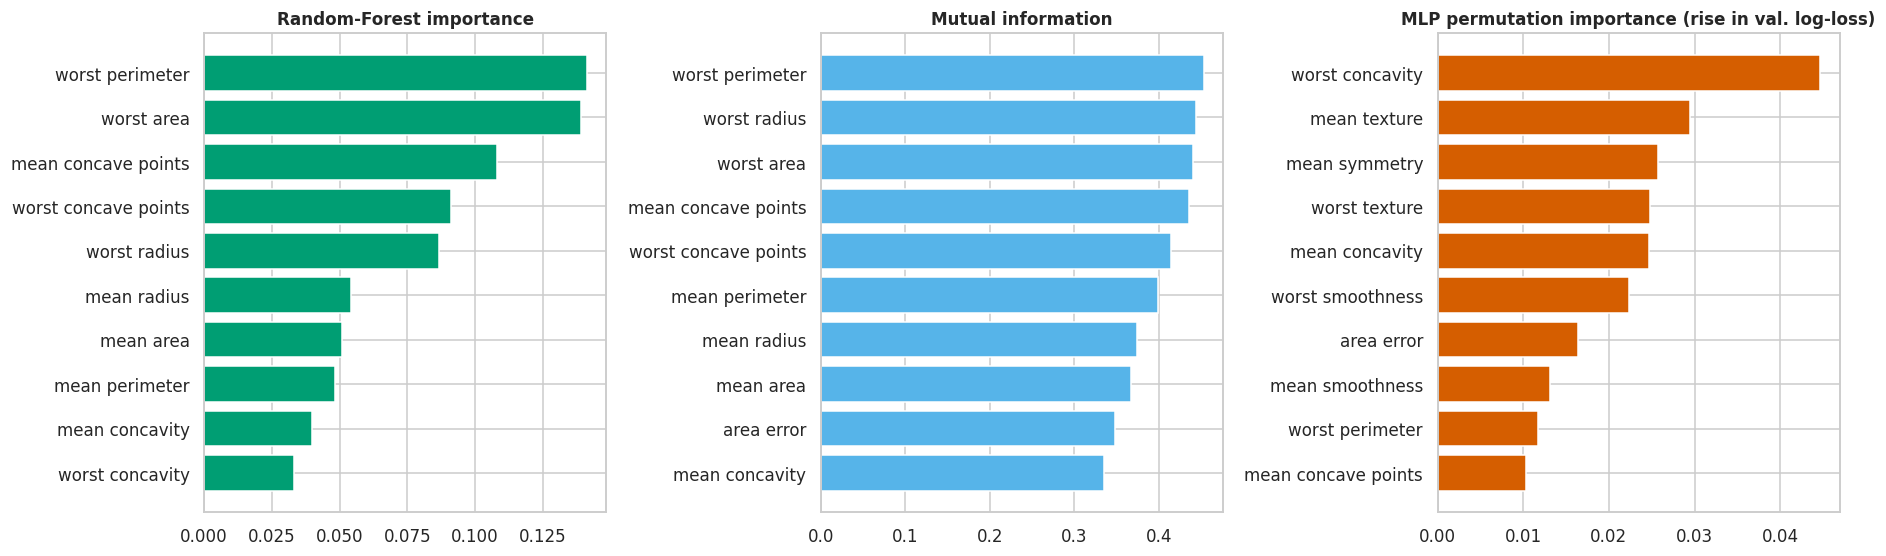

In [32]:
perm = permutation_importance(mlp, Z_va, y_va, scoring="neg_log_loss", n_repeats=30, random_state=SEED)
imp_perm = pd.Series(perm.importances_mean, index=FEATURES)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, s_, ttl, col in ((axes[0], imp_rf, "Random-Forest importance", "#009E73"), (axes[1], imp_mi, "Mutual information", "#56B4E9"),
                         (axes[2], imp_perm, "MLP permutation importance (rise in val. log-loss)", "#D55E00")):
    t = s_.sort_values(ascending=False).head(10)[::-1]
    ax.barh([i.replace("_", " ") for i in t.index], t.values, color=col); ax.set_title(ttl, fontsize=11)
finish("fig17_feature_importance.png")
metrics["importance"] = dict(rf=imp_rf.sort_values(ascending=False).head(5).round(3).to_dict(),
                             mi=imp_mi.sort_values(ascending=False).head(5).round(3).to_dict(),
                             perm=imp_perm.sort_values(ascending=False).head(5).round(4).to_dict())
# Rule of three: with 0 errors in n test cases, the 95 % upper bound of the true error rate is about 3/n
metrics["rule_of_three_err_upper"] = round(3 / len(y_te), 4)
print(metrics["importance"])

## SAVE ALL NUMBERS USED IN THE REPORT

In [33]:
metrics["n_figures"] = len(list(FIG.glob("fig*.png")))
with open(OUT / "metrics.json", "w") as fh:
    json.dump(metrics, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved outputs/metrics.json |", metrics["n_figures"], "figures in figures/")

Saved outputs/metrics.json | 17 figures in figures/
